In [3]:
import pandas as pd


#importar e verificar dados#

df = pd.read_csv("../data/Telco_customer_churn.csv", sep=";", decimal=",")
df.shape


(7043, 33)

In [4]:
#entender a estrutura das data#
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [5]:
#Entender o conteudo da dataset#
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,"108,15",Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,"151,65",Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,"820,5",Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,"3046,05",Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,"5036,3",Yes,1,89,5340,Competitor had better devices


In [6]:
#Entendimento do Churn Level
# No: Qtd clientes não cancelaram
# SI: Qtd clientes cancelaram #

df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [7]:
#execução e verificação de formato e correção#

total_charges_numerico = pd.to_numeric(df["Total Charges"].str.replace(",", "."), errors="coerce")
filas_problema = df[total_charges_numerico.isnull()]
filas_problema[["CustomerID", "Tenure Months", "Total Charges"]]


,CustomerID,Tenure Months,Total Charges
2234,4472-LVYGI,0,
2438,3115-CZMZD,0,
2568,5709-LVOEQ,0,
2667,4367-NUYAO,0,
2856,1371-DWPAZ,0,
4331,7644-OMVMY,0,
4687,3213-VVOLG,0,
5104,2520-SGTTA,0,
5719,2923-ARZLG,0,
6772,4075-WKNIU,0,


In [8]:
df["Total Charges"] = total_charges_numerico.fillna(0)
df["Total Charges"].dtype

dtype('float64')

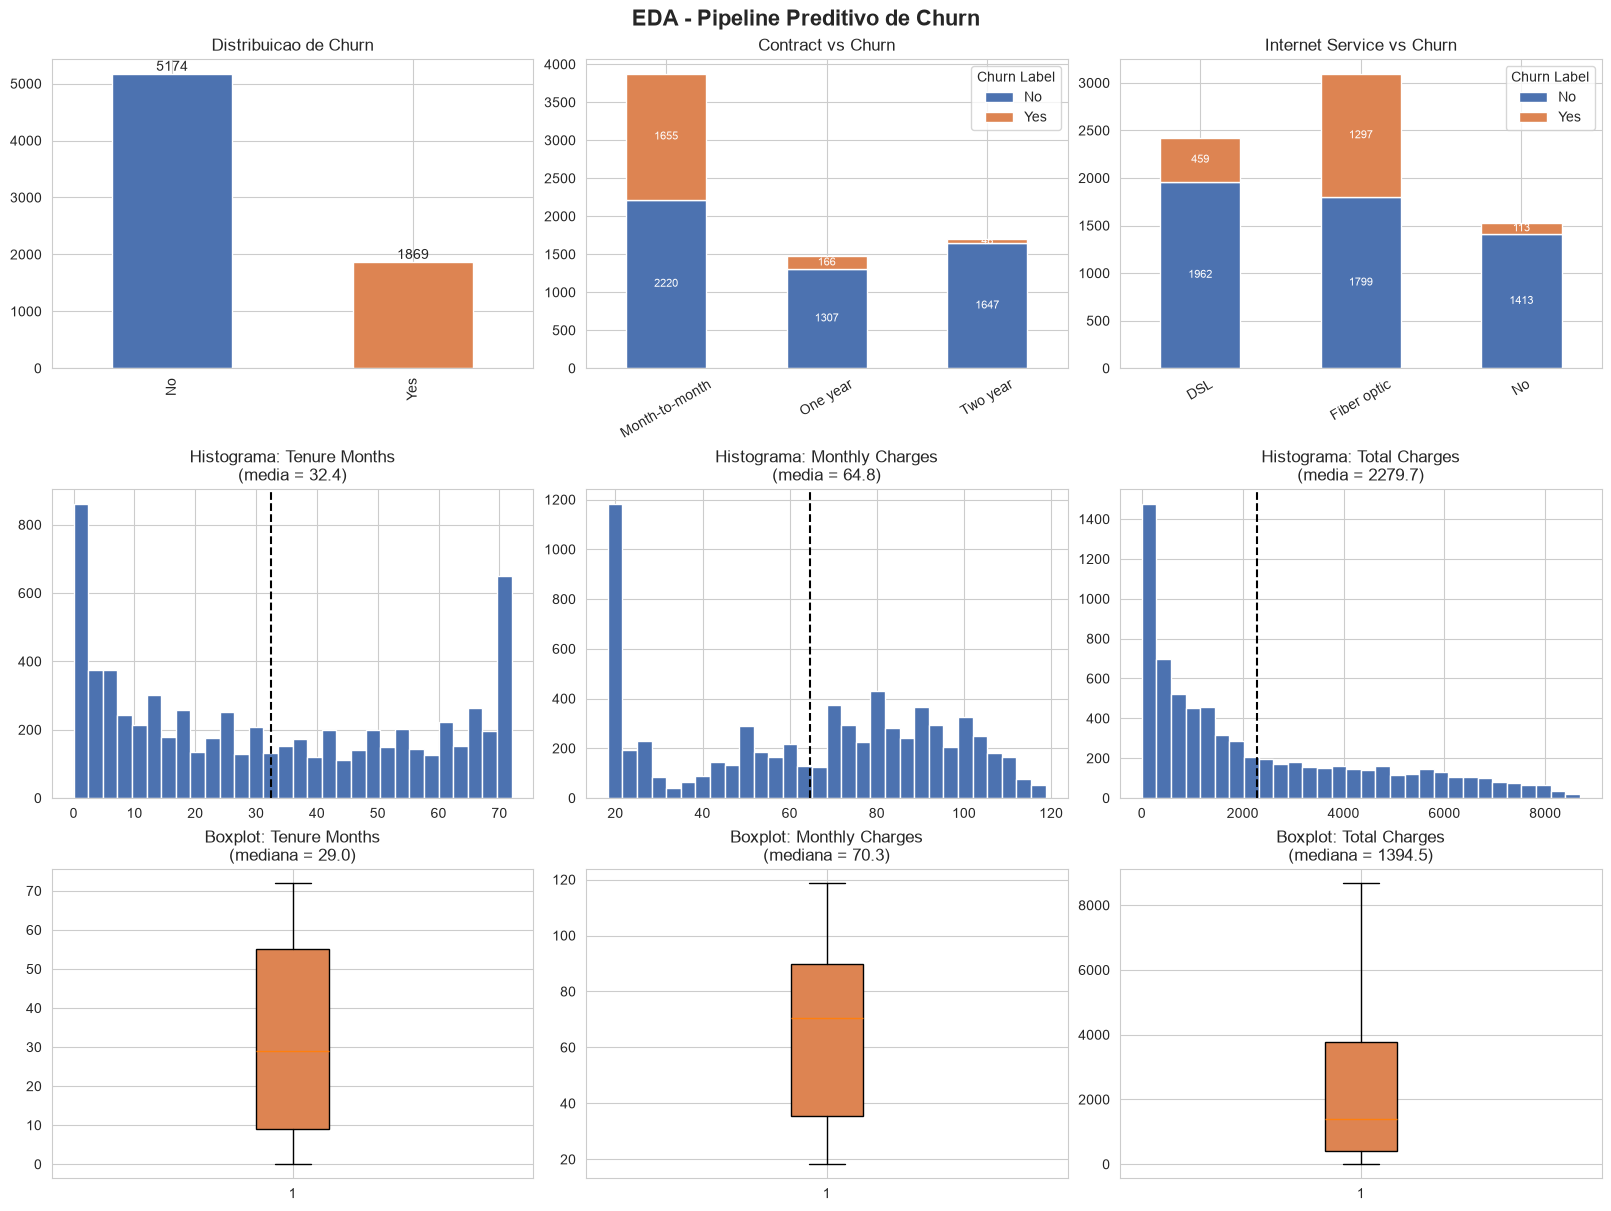

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
paleta = ["#4C72B0", "#DD8452"]

fig, axes = plt.subplots(
    3, 3, figsize=(16, 12),
    constrained_layout=True,
)
fig.suptitle(
    "EDA - Pipeline Preditivo de Churn",
    fontsize=16,
    fontweight="bold",
)

ax0 = df["Churn Label"].value_counts().plot(
    kind="bar",
    ax=axes[0, 0],
    color=paleta,
)
axes[0, 0].set_title("Distribuicao de Churn")
axes[0, 0].set_xlabel("")
for container in ax0.containers:
    ax0.bar_label(container)

tab_contract = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
)
ax1 = tab_contract.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 1],
    color=paleta,
)
axes[0, 1].set_title("Contract vs Churn")
axes[0, 1].set_xlabel("")
axes[0, 1].tick_params(
    axis="x",
    rotation=30,
)
for container in ax1.containers:
    ax1.bar_label(
        container,
        label_type="center",
        color="white",
        fontsize=8,
    )

tab_internet = pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
)
ax2 = tab_internet.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 2],
    color=paleta,
)
axes[0, 2].set_title("Internet Service vs Churn")
axes[0, 2].set_xlabel("")
axes[0, 2].tick_params(
    axis="x",
    rotation=30,
)
for container in ax2.containers:
    ax2.bar_label(
        container,
        label_type="center",
        color="white",
        fontsize=8,
    )

cols_numericas = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
]

nl = "\n"

for i, col in enumerate(cols_numericas):
    media = df[col].mean()
    axes[1, i].hist(
        df[col],
        bins=30,
        color="#4C72B0",
    )
    axes[1, i].axvline(
        media,
        color="black",
        linestyle="--",
        linewidth=1.5,
    )
    titulo_hist = "Histograma: " + col
    titulo_hist += nl
    titulo_hist += f"(media = {media:.1f})"
    axes[1, i].set_title(titulo_hist)

    mediana = df[col].median()
    axes[2, i].boxplot(
        df[col],
        patch_artist=True,
        boxprops=dict(facecolor="#DD8452"),
    )
    titulo_box = "Boxplot: " + col
    titulo_box += nl
    titulo_box += f"(mediana = {mediana:.1f})"
    axes[2, i].set_title(titulo_box)

plt.show()

In [10]:
df[["Tenure Months", "Monthly Charges", "Total Charges"]].describe()

,Tenure Months,Monthly Charges,Total Charges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


In [11]:
cols_corr = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "Churn Value",
]

matriz_corr = df[cols_corr].corr()
print (matriz_corr)




                 Tenure Months  Monthly Charges  Total Charges  Churn Value
Tenure Months         1.000000         0.247900       0.826178    -0.352229
Monthly Charges       0.247900         1.000000       0.651174     0.193356
Total Charges         0.826178         0.651174       1.000000    -0.198324
Churn Value          -0.352229         0.193356      -0.198324     1.000000


Observação — Viés de janela de observação no Churn Label #O dataset define Churn Label com uma janela temporal fixa: "Yes = o cliente saiu da empresa # neste trimestre; No = o cliente permaneceu neste trimestre". Isso significa que a variável-alvo não # é ambígua — ela responde a uma pergunta bem delimitada ("cancelou neste trimestre?"), e não "vai # cancelar algum dia?".

Porém, isso introduz um viés conhecido em problemas de churn: clientes com Tenure Months baixo tiveram menos tempo de exposição dentro do trimestre para efetivamente cancelar, em comparação com clientes de 
tenure alto. Ou seja, um "No" em um cliente novo carrega mais incerteza do que um "No" em um cliente de  longa data — não podemos assumir que ambos representam o mesmo grau de "retenção comprovada".
#Decisão adotada: não redefinir o target (isso descaracterizaria o problema de negócio pedido e reduziria
a base de dados), e sim manter Tenure Months como feature no modelo, permitindo que o próprio modelo 
capture esse efeito. Fica documentado como limitação conhecida do modelo, a ser citada no Model Card 
(viés de exposição / janela de observação).#

## Conclusão da Análise Exploratória (EDA)

### Balanceamento do target
O target `Churn Label` está desbalanceado: 5.174 clientes "No" (73,5%) vs. 1.869 "Yes" (26,5%).
Isso significa que a acurácia sozinha seria uma métrica enganosa para avaliar o modelo — será
necessário priorizar métricas sensíveis à classe minoritária (recall, F1, AUC-ROC), decisão a ser
formalizada no Passo 6.

Vale destacar que `Churn Label` tem uma janela de observação fixa (cancelou ou não **neste
trimestre**), não um desfecho definitivo e permanente. Isso introduz um viés conhecido: clientes
com `Tenure Months` baixo tiveram menos tempo de exposição dentro do trimestre para efetivamente
cancelar, então um "No" em um cliente novo carrega mais incerteza que um "No" em um cliente
antigo. Essa limitação já está documentada no ML Canvas (seção de riscos e vieses) e será
mencionada novamente no Model Card.

### Outliers
Aplicando o método do intervalo interquartil (1,5×IQR) sobre as três variáveis numéricas
(`Tenure Months`, `Monthly Charges`, `Total Charges`), **nenhuma** apresentou valores fora do
intervalo esperado. Não há necessidade de tratamento de outliers nesta base.

### Variáveis categóricas com sinal aparente de churn
- **`Contract`**: clientes com contrato *month-to-month* cancelam com frequência muito maior que
  clientes com contrato de 1 ou 2 anos — coerente com a hipótese de que menor compromisso
  contratual facilita o cancelamento.
- **`Internet Service`**: clientes com fibra óptica mostram maior propensão a cancelar, embora de
  forma menos acentuada que o padrão observado em `Contract`.
- **`Paperless Billing`**: clientes com faturamento eletrônico cancelam mais que o dobro dos que
  recebem fatura em papel (33,6% vs. 16,3%). É pouco provável que o método de faturamento em si
  seja causa direta do cancelamento — mais provavelmente atua como *proxy* de outro perfil de
  cliente (ex.: maior sobreposição com contratos month-to-month ou pagamento via electronic
  check). Mesmo sem uma explicação causal direta, o sinal estatístico é relevante para um modelo
  preditivo.

As demais variáveis categóricas mantidas não foram auditadas individualmente nesta etapa — serão
avaliadas de forma objetiva e simultânea através dos coeficientes do modelo baseline (Passo 7).

### Variáveis mantidas, transformadas e descartadas

**Numéricas mantidas (3):** `Tenure Months`, `Monthly Charges`, `Total Charges`

**Categóricas mantidas (16):** `Gender`, `Senior Citizen`, `Partner`, `Dependents`, `Phone
Service`, `Multiple Lines`, `Internet Service`, `Online Security`, `Online Backup`, `Device
Protection`, `Tech Support`, `Streaming TV`, `Streaming Movies`, `Contract`, `Paperless Billing`,
`Payment Method`

**Target:** `Churn Label` / `Churn Value`

**Descartadas e motivo:**
- `CustomerID`, `Count` — identificadores sem valor preditivo
- `Country`, `State` — variância zero (único valor em toda a base)
- `City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude` — alta cardinalidade, quase-identificam
  o cliente; exigiriam engenharia geoespacial fora do escopo deste baseline
- `Churn Score`, `CLTV` — saída de outro modelo preditivo (vazamento de dados)
- `Churn Reason` — só existe para quem já cancelou (vazamento de dados)

### Tratamento de dados aplicado
- **Nulos:** nenhuma coluna apresentou valores nulos, exceto `Churn Reason` (5.174 nulos,
  esperado — só clientes que cancelaram têm motivo registrado). Como essa coluna já foi excluída
  por vazamento de dados, nenhuma tratativa de nulos foi necessária nas features finais.
- **`Total Charges`:** veio como tipo `str` porque 11 linhas estavam em branco (clientes com
  `Tenure Months = 0`, sem ciclo de cobrança fechado). Aplicado `pd.to_numeric` com substituição
  de vírgula por ponto decimal e `errors="coerce"` para capturar os brancos como `NaN`, seguido de
  `fillna(0)` — zero faz sentido de negócio para quem ainda não fechou um ciclo de cobrança.
  Coluna convertida para `float64`.


  **Métrica técnica principal: Recall**, com objetivo de referência entre 0,70 e 0,80 (benchmark de
indústria para problemas de churn — ver ML Canvas, seções 1 e 6). Justificativa: conforme definido
no ML Canvas (seção 5), um falso negativo (não detectar um cliente que realmente vai cancelar) é
mais custoso que um falso positivo (oferecer um benefício de retenção a quem não ia sair), pois
perder um cliente implica o custo de atrair um novo. Além disso, o target está desbalanceado
(73,5% "No" vs. 26,5% "Yes"), o que torna a acurácia uma métrica enganosa — um modelo que sempre
prevê "não vai cancelar" já atingiria ~73,5% de acurácia sem nenhum poder preditivo real.

**Métrica secundária de referência: F1-score.** Usada como leitura-resumo complementar, para
evitar que a otimização de recall leve o modelo a classificar a maioria dos clientes como "alto
risco" apenas para maximizar a detecção de churners, ignorando a precisão.

**Métrica de negócio:** percentual de clientes com risco real de cancelamento efetivamente
detectados sobre o total de churners reais — a mesma lógica do recall, mas expressa em termos que
a gerência de clientes usa para acompanhar o impacto das campanhas de retenção (ver ML Canvas,
seção 4).

In [ ]:
#SPLIT TREINAMENTO / TEST
#Estratificação de variaveis, categoricas e numericas -> Treinamento e Test

from sklearn.model_selection import train_test_split

#clasificação de variaveis numericas e categoricas

numeric_cols = ["Tenure Months","Monthly Charges","Total Charges",]

categorical_cols = [
    "Gender", "Senior Citizen", "Partner", "Dependents",
    "Phone Service", "Multiple Lines", "Internet Service",
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies",
    "Contract", "Paperless Billing", "Payment Method",
]

#Data frame - definição de Features e Target
X = df[numeric_cols+categorical_cols]
y = df['Churn Value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42,)

X_train.shape, X_test.shape

((5634, 19), (1409, 19))

In [ ]:
#TREINAMENTO DE MODELO -> Regresão Logistica
# Tratamento de variaveis, Categoricas (OneHotEncoder), Numericas (Standard Scaler)
# Aplicação de Pipeline de Treinamento

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing  import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

modelo_baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

modelo_baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['Tenure Months','Monthly Charges','Total Charges',...,'Contract', 'Paperless Billing','Payment Method']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

In [ ]:

#APLICAÇÃO E REVISÃO DE METRICAS

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
import joblib

y_pred = modelo_baseline.predict(X_test)
y_proba = modelo_baseline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("Matriz de confusao:")
print(confusion_matrix(y_test, y_pred))
print(f"AUC-ROC: {roc_auc_score(y_test, y_proba):.3f}")

joblib.dump(
    modelo_baseline,
    "../models/baseline_logistic_regression.pkl",
)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409

Matriz de confusao:
[[917 118]
 [161 213]]
AUC-ROC: 0.849


['../models/baseline_logistic_regression.pkl']

In [44]:
#REVISÃO DE CORRELAÇÃO DE FEATURES


import pandas as pd

feature_names = modelo_baseline.named_steps["preprocessor"].get_feature_names_out()
coeficientes = modelo_baseline.named_steps["classifier"].coef_[0]

df_coef = pd.DataFrame({
    "feature": feature_names,
    "coeficiente": coeficientes,
})




df_coef["coef_abs"] = df_coef["coeficiente"].abs()
df_coef = df_coef.sort_values("coef_abs", ascending=False)



In [45]:
# las 10 variables con menor impacto (candidatas a "no aportar")
df_coef.sort_values("coef_abs").head(46)



,feature,coeficiente,coef_abs
41,cat__Paperless Billing_Yes,0.006465,0.006465
22,cat__Online Backup_No,0.007448,0.007448
27,cat__Device Protection_Yes,-0.020161,0.020161
8,cat__Partner_Yes,-0.026157,0.026157
25,cat__Device Protection_No,-0.038509,0.038509
24,cat__Online Backup_Yes,-0.066118,0.066118
15,cat__Multiple Lines_Yes,0.081648,0.081648
28,cat__Tech Support_No,0.114846,0.114846
45,cat__Payment Method_Mailed check,-0.117796,0.117796
11,cat__Phone Service_No,-0.126135,0.126135


## Passo 8 — Leitura dos Resultados do Baseline (Conclusão da Etapa 1)

### O baseline é um piso razoável?
Sim. O `AUC-ROC = 0,849` mostra que o modelo tem capacidade real de separar clientes com risco
de churn dos que não têm — bem acima do 0,5 esperado de um modelo aleatório. Isso confirma que os
padrões identificados na EDA (Passo 5) carregam sinal preditivo de verdade, não são apenas ruído
visual dos gráficos.

### Leitura das métricas
A **acurácia (0,80)** é enganosa neste problema: um modelo ingênuo que sempre previsse "não vai
cancelar" já atingiria 73,5% de acurácia, dado o desbalanceamento do target. O modelo real melhora
isso em apenas 6,5 pontos percentuais, apesar de ter aprendido um padrão genuíno — a acurácia
esconde esse aprendizado porque é dominada pelo bom desempenho na classe majoritária (recall de
0,89 na classe "No Churn").

O **recall da classe 1 (churn) é 0,57**, abaixo do objetivo de referência definido no Passo 6
(0,70–0,80, ver ML Canvas). Na prática: **43% dos clientes que realmente cancelam** (161 de 374 no
conjunto de teste) não são detectados pelo modelo e, portanto, não seriam contatados pela campanha
de retenção — exatamente o cenário de maior custo definido no ML Canvas (seção 5).

O **F1-score (0,60)** reflete esse equilíbrio imperfeito entre precisão (0,64) e recall (0,57).

A combinação de **AUC alto (0,849) com recall baixo no limiar padrão (0,5)** indica que o problema
não é a falta de capacidade preditiva do modelo, e sim que o limiar de decisão padrão não está
calibrado para a prioridade de negócio definida (priorizar recall sobre precisão). Ajustar esse
limiar é uma otimização a ser avaliada nas próximas etapas, uma vez definido o modelo campeão.

### Coeficientes — o que pesa mais no modelo
As variáveis com maior peso (em valor absoluto) confirmam as hipóteses levantadas na EDA (Passo 5):

| Variável | Coeficiente | Direção |
|---|---|---|
| `Tenure Months` | -1,270 (a mais forte de todas) | Mais antiguidade → menos churn |
| `Dependents_Yes` | -0,989 | Ter dependentes → menos churn |
| `Contract_Two year` | -0,735 | Contrato de 2 anos → menos churn |
| `Dependents_No` | +0,645 | Sem dependentes → mais churn |
| `Internet Service_DSL` | -0,609 | DSL → menos churn |
| `Contract_Month-to-month` | +0,564 | Contrato mês a mês → mais churn |
| `Internet Service_Fiber optic` | +0,550 | Fibra óptica → mais churn |

`Tenure Months` como coeficiente mais forte reforça a hipótese do Passo 5 sobre o segmento de
clientes novos/frágeis. `Contract` e `Internet Service` confirmam os padrões já vistos nos
crosstabs. `Dependents` surge como um sinal forte não explorado anteriormente, com lógica de
negócio plausível (clientes com dependentes estão mais "presos" ao serviço).

No outro extremo, variáveis como `Paperless Billing`, `Online Backup`, `Device Protection`,
`Partner` e `Multiple Lines` têm coeficientes muito próximos de zero (abaixo de 6,5% do
coeficiente mais forte) — baixo aporte no modelo multivariado. Vale destacar o caso de
`Paperless Billing`: no crosstab univariado (Passo 5) parecia relevante (33,6% vs. 16,3% de
churn), mas seu coeficiente no modelo multivariado é quase nulo — evidência de que aquela
associação era um proxy de outras variáveis (`Contract`, `Payment Method`), sem efeito
independente real.

### Nota técnica — multicolinearidade entre variáveis numéricas
`Monthly Charges` (-0,498) e `Total Charges` (+0,522) apresentam sinais que exigem leitura
cautelosa: seria esperado que cobranças mensais mais altas aumentassem o risco de churn (preço
como motivo de cancelamento), mas o coeficiente é negativo. Essa inversão é consistente com a
multicolinearidade identificada na matriz de correlação do Passo 4 (`Total Charges` correlaciona
0,826 com `Tenure Months` e 0,651 com `Monthly Charges`). Quando variáveis correlacionadas
competem no mesmo modelo, o crédito preditivo se distribui de forma instável entre elas, e os
sinais individuais podem não refletir o efeito real e isolado de cada variável. As três variáveis
foram mantidas no modelo — a multicolinearidade não invalida o poder preditivo conjunto (refletido
no AUC), mas limita a confiabilidade da interpretação individual desses dois coeficientes
específicos. Fica documentado como limitação conhecida, a citar também no Model Card (Etapa 4).

### O que falta — justificativa para a Etapa 2
A regressão logística assume uma relação monotônica (log-linear) entre cada variável e a
probabilidade de churn. Se o padrão real envolver combinações não lineares entre variáveis (por
exemplo, o efeito de `Tenure Months` pode não ser o mesmo em todos os níveis de `Monthly
Charges`), um modelo linear está limitado por desenho para capturá-las — independentemente de
quão bem ajustado esteja. Isso, somado ao recall abaixo do objetivo, justifica testar modelos
capazes de capturar relações mais complexas (Random Forest e MLP) na Etapa 2, usando este baseline
como piso de comparação.

### Conclusão da Etapa 1
O baseline de Regressão Logística confirma que existe sinal preditivo real nos dados (AUC 0,849) e
valida as principais hipóteses da EDA (`Tenure Months`, `Contract`, `Internet Service` como
variáveis-chave), mas ainda não atinge o objetivo de negócio definido (recall 0,57 vs. 0,70–0,80),
deixando 43% dos churners reais sem detecção. Esse resultado define o piso a ser superado na
Etapa 2.